# Day 3 Project — The State Health Ministry Briefing
**Sampling + Robust Statistics** · Python check of every hand-worked answer.

A random sample of **n = 10** pregnant women was drawn from a register of **N = 1,000**; haemoglobin (Hb, g/dL) was measured.

In [1]:
import numpy as np
import math

hb = np.array([10.2, 11.5, 9.8, 12.0, 10.6, 11.1, 10.4, 11.8, 9.5, 5.1])
N = 1000
print("n =", len(hb))
print("Sorted:", np.sort(hb))

n = 10
Sorted: [ 5.1  9.5  9.8 10.2 10.4 10.6 11.1 11.5 11.8 12. ]


## Step 1 — Centre: mean and median

In [2]:
mean = hb.mean()
median = np.median(hb)
print(f"Sum    = {hb.sum():.1f}")
print(f"Mean   = {mean:.2f} g/dL")
print(f"Median = {median:.2f} g/dL")

Sum    = 102.0
Mean   = 10.20 g/dL
Median = 10.50 g/dL


## Step 2 — Spread: variance and SD
`ddof=1` divides by **n − 1**: the 10 women are a *sample* used to estimate the clinic's spread, and dividing by n − 1 (Bessel's correction) makes the variance an unbiased estimate of the population variance.

In [3]:
dev = hb - mean
ss = (dev**2).sum()
var = hb.var(ddof=1)
sd = hb.std(ddof=1)
print("Squared deviations:", np.round(dev**2, 2))
print(f"Sum of squares SS = {ss:.2f}")
print(f"Variance s^2 = SS/(n-1) = {ss:.2f}/{len(hb)-1} = {var:.4f}")
print(f"SD s = {sd:.4f} g/dL")

Squared deviations: [ 0.    1.69  0.16  3.24  0.16  0.81  0.04  2.56  0.49 26.01]
Sum of squares SS = 35.16
Variance s^2 = SS/(n-1) = 35.16/9 = 3.9067
SD s = 1.9765 g/dL


## Step 3 — Quartiles by linear interpolation
NumPy's default `method='linear'` uses position L = (n − 1)p + 1, the same rule used by hand.

In [4]:
def quartiles(x):
    q1, q2, q3 = np.percentile(x, [25, 50, 75], method="linear")
    return q1, q2, q3, q3 - q1

# hand formula, to show the interpolation explicitly
def interp_quantile(x, p):
    s = np.sort(x); L = (len(s) - 1) * p + 1          # 1-based position
    lo = int(math.floor(L)); frac = L - lo
    val = s[lo-1] + frac * (s[min(lo, len(s)-1)] - s[lo-1])
    return L, val

for p in (0.25, 0.5, 0.75):
    L, v = interp_quantile(hb, p)
    print(f"p={p}: position L={L:.2f} -> {v:.2f}")

q1, q2, q3, iqr = quartiles(hb)
print(f"\nQ1 = {q1:.2f}, Q2 = {q2:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")

p=0.25: position L=3.25 -> 9.90
p=0.5: position L=5.50 -> 10.50
p=0.75: position L=7.75 -> 11.40

Q1 = 9.90, Q2 = 10.50, Q3 = 11.40, IQR = 1.50


## Step 4 — 1.5 × IQR fences

In [5]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = hb[(hb < lower) | (hb > upper)]
print(f"Lower fence = {lower:.2f} g/dL")
print(f"Upper fence = {upper:.2f} g/dL")
print("Outliers:", outliers)
print("Is 5.1 an outlier?", 5.1 in outliers)

Lower fence = 7.65 g/dL
Upper fence = 13.65 g/dL
Outliers: [5.1]
Is 5.1 an outlier? True


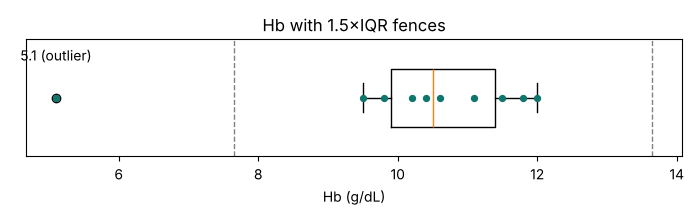

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 2.2))
ax.boxplot(hb, vert=False, whis=1.5, widths=0.5)
ax.scatter(hb, np.ones_like(hb), color="#0f766e", zorder=3, s=18)
for f in (lower, upper):
    ax.axvline(f, ls="--", color="grey", lw=1)
ax.annotate("5.1 (outlier)", (5.1, 1), xytext=(5.1, 1.32), ha="center")
ax.set_xlabel("Hb (g/dL)"); ax.set_yticks([])
ax.set_title("Hb with 1.5×IQR fences")
plt.tight_layout(); plt.show()

## Step 5 — Recompute without 5.1

In [7]:
hb9 = hb[hb != 5.1]
q1b, q2b, q3b, iqrb = quartiles(hb9)
rows = [("Mean",   mean,   hb9.mean()),
        ("Median", median, np.median(hb9)),
        ("SD",     sd,     hb9.std(ddof=1)),
        ("IQR",    iqr,    iqrb)]
print(f"{'Statistic':<8}{'With 5.1':>10}{'Without':>10}{'Change':>9}")
for name, a, b in rows:
    print(f"{name:<8}{a:>10.3f}{b:>10.3f}{b-a:>+9.3f}")
print(f"\nWithout 5.1: Q1 = {q1b:.2f}, Q3 = {q3b:.2f}, variance = {hb9.var(ddof=1):.4f}")

Statistic  With 5.1   Without   Change
Mean        10.200    10.767   +0.567
Median      10.500    10.600   +0.100
SD           1.977     0.885   -1.092
IQR          1.500     1.300   -0.200

Without 5.1: Q1 = 10.20, Q3 = 11.50, variance = 0.7825


**Decision.** Report the **median and IQR (10.5 g/dL, IQR 1.5)**, because they barely move when 5.1 is removed (10.5→10.6, 1.5→1.3) while the mean and SD are distorted (SD more than halves). Treat 5.1 as a **real extreme, not an error**: Hb 5.1 g/dL is clinically possible (severe anaemia), so after confirming the reading it stays in the data. She most likely belongs to a **different, high-risk group** (severe anaemia) and should be referred urgently and tracked separately.

## Step 6 — Sample size
Standard error SE = σ/√n ≤ 0.25 ⇒ n ≥ (σ/0.25)².

In [8]:
sigma, target = 1.5, 0.25
n_req = math.ceil((sigma / target) ** 2)
print(f"n >= (1.5/0.25)^2 = {(sigma/target)**2:.1f} -> n = {n_req}")
print(f"Check SE(n=36) = {sigma/math.sqrt(36):.4f}")
print(f"Check SE(n=35) = {sigma/math.sqrt(35):.4f}  (too large)")

# optional finite-population correction (N = 1000)
n_fpc = n_req / (1 + (n_req - 1) / N)
print(f"With finite-population correction: {n_fpc:.2f} -> {math.ceil(n_fpc)} (negligible; recommend {n_req})")

n >= (1.5/0.25)^2 = 36.0 -> n = 36
Check SE(n=36) = 0.2500
Check SE(n=35) = 0.2535  (too large)
With finite-population correction: 34.78 -> 35 (negligible; recommend 36)


## Summary

In [9]:
print(f"1. Mean = {mean:.2f}, Median = {median:.2f}")
print(f"2. Variance = {var:.3f}, SD = {sd:.3f} (divisor n-1)")
print(f"3. Q1 = {q1:.2f}, Q2 = {q2:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"4. Fences = [{lower:.2f}, {upper:.2f}] -> 5.1 is an outlier")
print(f"5. Without 5.1: mean {hb9.mean():.2f}, median {np.median(hb9):.2f}, SD {hb9.std(ddof=1):.3f}, IQR {iqrb:.2f}")
print(f"6. Required sample size n = {n_req}")

1. Mean = 10.20, Median = 10.50
2. Variance = 3.907, SD = 1.977 (divisor n-1)
3. Q1 = 9.90, Q2 = 10.50, Q3 = 11.40, IQR = 1.50
4. Fences = [7.65, 13.65] -> 5.1 is an outlier
5. Without 5.1: mean 10.77, median 10.60, SD 0.885, IQR 1.30
6. Required sample size n = 36
